# Implementação de Regressão Linear do Zero e Análise de Qualidade de Vinhos

Este notebook apresenta a implementação completa de um modelo de **Regressão Linear Múltipla** otimizado via gradiente descendente . O modelo é aplicado a um problema real de predição de qualidade de vinhos, abrangendo etapas de pré-processamento, calibração de hiperparâmetros, avaliação de desempenho e análise de convergência.

## Sumário
1. [Importação de Bibliotecas](#1-importacao-de-bibliotecas)
2. [Implementação das Classes Principais](#2-implementacao-das-classes-principais)
   - 2.1. Classe `RTrainer` (Regressão Linear via Descida de Gradiente)
   - 2.2. Classe `Metricas` (MAE, MSE e MAPE)
3. [Testes Unitários e Validação Inicial](#3-testes-unitarios-e-validacao-inicial)
4. [Carregamento e Preparação do Dataset Real](#4-carregamento-e-preparacao-do-dataset-real)
5. [Padronização dos Dados](#5-padronizacao-dos-dados)
6. [Calibração da Taxa de Aprendizagem (*Learning Rate*)](#6-calibracao-da-taxa-de-aprendizagem-learning-rate)
7. [Treinamento do Modelo Final](#7-treinamento-do-modelo-final)
8. [Análise de Convergência (Curvas de Custo)](#8-analise-de-convergencia-curvas-de-custo)
9. [Análise e Interpretação dos Parâmetros ($\theta$)](#9-analise-e-interpretacao-dos-parametros-theta)
10. [Avaliação Quantitativa do Modelo](#10-avaliacao-quantitativa-do-modelo)
11. [Análise de  Tempo de Treinamento](#11-analise-de-desempenho-computacional-e-tempo-de-treinamento)
12. [Conclusão](#12-conclusao)

<a id="1-importacao-de-bibliotecas"></a>
## 1. Importação de Bibliotecas

Nesta etapa, importamos as bibliotecas essenciais para manipulação de dados (`pandas`, `numpy`), visualização (`matplotlib.pyplot`) e funções de apoio para divisão de bases de dados (`train_test_split`).

In [47]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

<a id="2-implementacao-das-classes-principais"></a>
## 2. Implementação das Classes Principais

Para manter o código modular e orientado a objetos, encapsulei a lógica de treinamento e as métricas de avaliação em classes dedicadas.

<a id="2-1-classe-rtrainer"></a>
### 2.1. Classe `RTrainer` (Regressão Linear via Descida de Gradiente)
A classe abaixo realiza o ajuste dos pesos theta iterativamente minimizando a função de Custo de Erro Quadrático Médio (MSE). O algoritmo atualiza os parâmetros seguindo a regra do gradiente.


In [48]:

class RTrainer:
    def __init__(self):
        self.theta = None
    def fit(self, X, y, learning_rate):
        X_novo = np.concatenate([np.ones((X.shape[0],1)), X], axis=1)
        n_parametros = X_novo.shape[1]
        theta = np.zeros(n_parametros)
        m = X_novo.shape[0]
        historico_custo = []
        for i in range(1000):
            y_pred = X_novo @ theta
            erro = y_pred - y
            fun_custo = np.mean((erro ** 2))
            gradiente = 2/m * (X_novo.T @ erro)
            theta = theta - learning_rate * gradiente
            historico_custo.append(fun_custo)
        self.theta = theta
        return self.theta
    def predict(self, X):
        X_novo = np.concatenate([np.ones((X.shape[0],1)), X], axis=1)
        y_pred = X_novo @ self.theta
        return y_pred
modelo = RTrainer()

<a id="2-2-classe-metricas"></a>
### 2.2. Classe `Metricas`

Implementação manual das principais métricas para avaliar o erro do modelo de regressão:
- **MAE (Erro Absoluto Médio):** Mede a magnitude média dos erros absolutos.
- **MSE (Erro Quadrático Médio):** Penaliza erros maiores de forma mais severa devido à quadratura.
- **MAPE (Erro Percentual Absoluto Médio):** Expressa o erro em termos percentuais relativos.

In [49]:
class Metricas:
    def __init__(self):
        pass

    def MAE(self, y, y_pred):
        erro = y_pred - y
        mae = np.mean(np.abs(erro))
        return mae

    def MSE(self, y, y_pred):
        erro = y_pred - y
        mse = np.mean(erro ** 2)
        return mse

    def MAPE(self, y, y_pred):
        erro = y_pred - y
        mape = np.mean(np.abs(erro / y) * 100)
        return mape

<a id="3-testes-unitarios-e-validacao-inicial"></a>
## 3. Testes Unitários e Validação Inicial

Antes de aplicar o modelo em dados reais, segue abaixo testes com conjuntos de dados sintéticos (*toy datasets*) para assegurar que as matrizes, interceptos e taxas de convergência funcionam matematicamente conforme o esperado.

In [50]:
# teste unitário método fit

X = np.array([[1], [2], [3], [4]])
y = np.array([10, 20, 30, 40])

modelo = RTrainer()
theta = modelo.fit(X, y, 0.01)
print(theta)

[0.15202261 9.94829378]


In [51]:
# teste unitário método predict
X = np.array([[1], [2], [3], [4]])
y = np.array([10, 20, 30, 40])
modelo = RTrainer()

modelo.fit(X, y, 0.01)

y_pred = modelo.predict(X)

print("Valores reais:", y)
print("Valores previstos:", y_pred)


Valores reais: [10 20 30 40]
Valores previstos: [10.10031638 20.04861016 29.99690393 39.94519771]


In [52]:
# teste funcional
X = np.array([[1], [2], [3], [4]])
y = np.array([5, 6, 7, 8])

modelo = RTrainer()
modelo.fit(X, y, 0.03)
modelo.predict(X)
print("Theta obtido:", modelo.theta)
print("Valores previstos:", modelo.predict(X))


Theta obtido: [3.99960409 1.00013466]
Valores previstos: [4.99973875 5.99987341 7.00000806 8.00014272]


In [53]:
#toy_dataset
X_toy = np.array([[1], [2], [3], [4]])
y_toy = np.array([2, 4, 6, 8])

modelo_toy = RTrainer()
modelo_toy.fit(X_toy, y_toy, 0.01)
y_pred_toy = modelo_toy.predict(X_toy)
mse_toy = np.mean(
    (y_toy - y_pred_toy) ** 2
)


print("Valores reais:", y_toy)
print("Valores previstos:", y_pred_toy)
print("MSE do toy dataset:", mse_toy)
assert mse_toy < 1e-3

print("Teste do toy dataset passou!")


Valores reais: [2 4 6 8]
Valores previstos: [2.02006328 4.00972203 5.99938079 7.98903954]
MSE do toy dataset: 0.00015439200722187687
Teste do toy dataset passou!


In [54]:
# Teste unitário das métricas

avaliador = Metricas()

y_teste_metricas = np.array([10, 20, 30])
y_pred_metricas = np.array([12, 18, 33])

print("MAE:", avaliador.MAE(
    y_teste_metricas,
    y_pred_metricas
))

print("MSE:", avaliador.MSE(
    y_teste_metricas,
    y_pred_metricas
))

print("MAPE:", avaliador.MAPE(
    y_teste_metricas,
    y_pred_metricas
))


MAE: 2.3333333333333335
MSE: 5.666666666666667
MAPE: 13.333333333333334


<a id="4-carregamento-e-preparacao-do-dataset-real"></a>
## 4. Carregamento e Preparação do Dataset Real

Foi utilizado o conjunto de dados de **Qualidade do Vinho (`winequality-red.csv`)**. O objetivo é prever a nota de qualidade do vinho com base em suas propriedades físico-químicas (como acidez, pH, teor alcoólico, entre outras).

A divisão dos dados foi subdividida  em três subconjuntos para garantir uma avaliação honesta:
* **Treino (64%):** Utilizado para ajustar os parâmetros do modelo.
* **Desenvolvimento / Validação (16%):** Utilizado para sintonizar hiperparâmetros (como a taxa de aprendizado $\alpha$).
* **Teste (20%):** Mantido isolado para a avaliação final e imparcial do modelo.

In [55]:
url = "https://raw.githubusercontent.com/danizin21/aprendizado-de-maquina/refs/heads/main/01-regressao-linear-qualidade-vinhos/data/winequality-red%20(1).csv"
df = pd.read_csv(url, sep=",")
X = df.drop("quality", axis=1)
y = df["quality"]

# Divisão inicial: Treino+Dev (80%) e Teste (20%)
X_treino_dev, X_teste, y_treino_dev, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)

# Subdivisão: Treino (80% do conjunto anterior -> 64% total) e Validação/Dev (20% -> 16% total)
X_treino, X_dev, y_treino, y_dev = train_test_split(X_treino_dev, y_treino_dev, test_size=0.2, random_state=42)

<a id="5-padronizacao-dos-dados"></a>
## 5. Padronização dos Dados
>  Para garantir a robustez estatística e evitar o vazamento de dados (*data leakage*), a média e o desvio padrão são calculados **estritamente sobre o conjunto de treino**. Em seguida, esses mesmos parâmetros são aplicados para transformar os conjuntos de validação e teste.

In [56]:
# Padronização correta usando as médias e desvios padrão calculados estritamente sobre o conjunto de treino
media = X_treino.mean()
desvio = X_treino.std()

X_treino = (X_treino - media) / desvio
X_dev = (X_dev - media) / desvio
X_teste = (X_teste - media) / desvio


<a id="6-calibracao-da-taxa-de-aprendizagem-learning-rate"></a>
## 6. Calibração da Taxa de Aprendizagem (*Learning Rate*)

Foi testado um conjunto de valores de learning rate entre 0.01 e 0.10, avaliando o desempenho por meio do MSE obtido no conjunto de desenvolvimento. O valor que apresentou o menor MSE foi selecionado para o treinamento final.

In [57]:
learning_rates = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.10]
resultados = []

for taxa in learning_rates:
    modelo = RTrainer()
    modelo.fit(X_treino, y_treino, taxa)
    y_pred_dev = modelo.predict(X_dev)
    mse = np.mean((y_pred_dev - y_dev) ** 2)
    resultados.append((taxa, mse))

print(resultados)

[(0.01, np.float64(0.42015561956109543)), (0.02, np.float64(0.4211837826917456)), (0.03, np.float64(0.4214076207518823)), (0.04, np.float64(0.4214690414458462)), (0.05, np.float64(0.42148642347662335)), (0.06, np.float64(0.4214913508547921)), (0.07, np.float64(0.42149274577228923)), (0.08, np.float64(0.4214931400360695)), (0.09, np.float64(0.4214932512928805)), (0.1, np.float64(0.4214932826378792))]


In [58]:
melhor_taxa, menor_mse = min(resultados, key=lambda x: x[1])

print("Melhor learning rate:", melhor_taxa)
print("Menor MSE:", menor_mse)

Melhor learning rate: 0.01
Menor MSE: 0.42015561956109543


<a id="7-treinamento-do-modelo-final"></a>
## 7. Treinamento do Modelo Final

Com a taxa de aprendizado otimizada, une-se os conjuntos de treino e desenvolvimento para maximizar a quantidade de informação disponível, treinando o modelo final com todos os exemplos de ajuste disponíveis.

In [59]:
# Junção de treino e dev para o treinamento final
X_treino_final = np.concatenate((X_treino, X_dev))
y_treino_final = np.concatenate((y_treino, y_dev))

modelo_final = RTrainer()
modelo_final.fit(X_treino_final,y_treino_final, melhor_taxa)

y_pred_teste = modelo_final.predict(X_teste)
mse_teste = np.mean((y_pred_teste - y_teste) ** 2)

print("MSE no conjunto de teste:", mse_teste)

MSE no conjunto de teste: 0.3898347216188115


### Avaliação no conjunto de teste
Após o treinamento utilizando os conjuntos de treino e desenvolvimento, o modelo foi avaliado no conjunto de teste, que permaneceu isolado durante as etapas de treinamento e calibração. O valor obtido para o MSE é apresentado na célula de execução acima.


<a id="8-analise-de-convergencia-curvas-de-custo"></a>
## 8. Análise de Convergência (Curvas de Custo)

Analisar o comportamento da função de custo ao longo das iterações é fundamental para diagnosticar se o modelo convergiu adequadamente e se a taxa de aprendizado escolhida foi eficiente (evitando oscilações bruscas ou estagnação precoce).

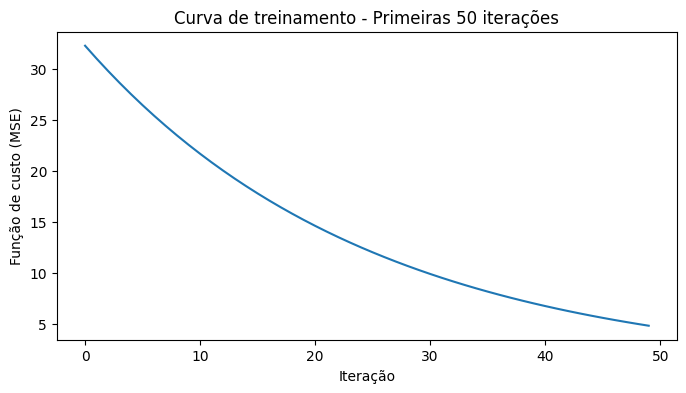

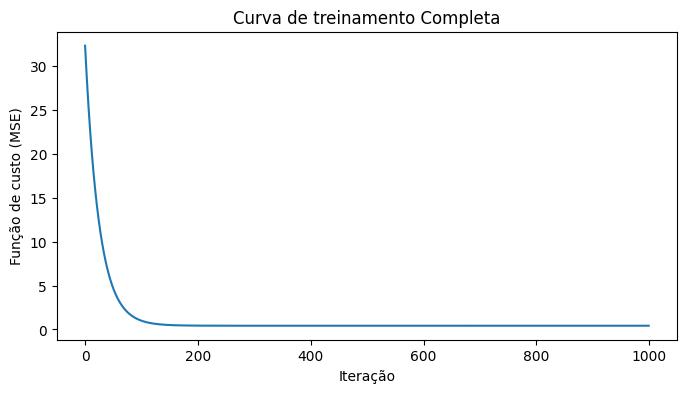

In [60]:
class RTrainer:
    def __init__(self):
        self.theta = None
        self.historico_custo = []

    def fit(self, X, y, learning_rate):
        X_novo = np.concatenate(
            [np.ones((X.shape[0], 1)), X],
            axis=1
        )

        n_parametros = X_novo.shape[1]
        theta = np.zeros(n_parametros)
        m = X_novo.shape[0]

        self.historico_custo = []

        for i in range(1000):
            y_pred = X_novo @ theta

            erro = y_pred - y

            fun_custo = np.mean(erro ** 2)

            gradiente = (2 / m) * (X_novo.T @ erro)

            theta = theta - learning_rate * gradiente

            self.historico_custo.append(fun_custo)

        self.theta = theta

        return self.theta

    def predict(self, X):
        X_novo = np.concatenate(
            [np.ones((X.shape[0], 1)), X],
            axis=1
        )

        return X_novo @ self.theta
modelo_grafico = RTrainer()
modelo_grafico.fit(X_treino_final,y_treino_final, melhor_taxa)

# Plotando as primeiras 50 iterações
plt.figure(figsize=(8, 4))
plt.plot(modelo_grafico.historico_custo[:50])
plt.xlabel("Iteração")
plt.ylabel("Função de custo (MSE)")
plt.title("Curva de treinamento - Primeiras 50 iterações")
plt.show()

# Plotando a curva completa
plt.figure(figsize=(8, 4))
plt.plot(modelo_grafico.historico_custo)
plt.xlabel("Iteração")
plt.ylabel("Função de custo (MSE)")
plt.title("Curva de treinamento Completa")
plt.show()


# Análise da Curva de Treinamento e Convergência
A análise da curva de custo ao longo das iterações demonstra o comportamento esperado e adequado do algoritmo de Gradiente Descendente aplicado ao conjunto de treinamento final, formado pela união dos conjuntos de treino e desenvolvimento.

Observando o gráfico referente às primeiras 50 iterações, nota-se uma queda acentuada e linear da função de erro quadrático médio (MSE), o que evidencia que o modelo está ajustando os parâmetros de forma agressiva e eficiente na direção do mínimo global no início do treinamento.

Já na curva completa (1000 iterações), o gráfico exibe o comportamento assintótico clássico de convergência. A estabilização da função de custo indica que o modelo atingiu uma região de convergência, e as 1000 iterações foram suficientes para que não fossem observadas reduções relevantes adicionais no custo.

<a id="9-analise-e-interpretacao-dos-parametros-theta"></a>
## 9. Análise e Interpretação dos Parâmetros (Theta)

Após a convergência do algoritmo de descida de gradiente, obtivemos o vetor de pesos theta e o viés (intercepto) do modelo. Como os dados foram previamente padronizados, os coeficientes permitem avaliar diretamente o impacto relativo de cada característica físico-química na nota de qualidade do vinho:

* **Magnitude e Direção:** Coeficientes com valores absolutos maiores exercem maior influência na predição da qualidade. Valores positivos indicam uma relação diretamente proporcional (o aumento da característica tende a elevar a nota do vinho), enquanto valores negativos indicam uma relação inversamente proporcional.
* **Intercepto (theta_Zero):** Representa a predição esperada da qualidade do vinho quando todas as características de entrada encontram-se em seus valores médios (devido à padronização).

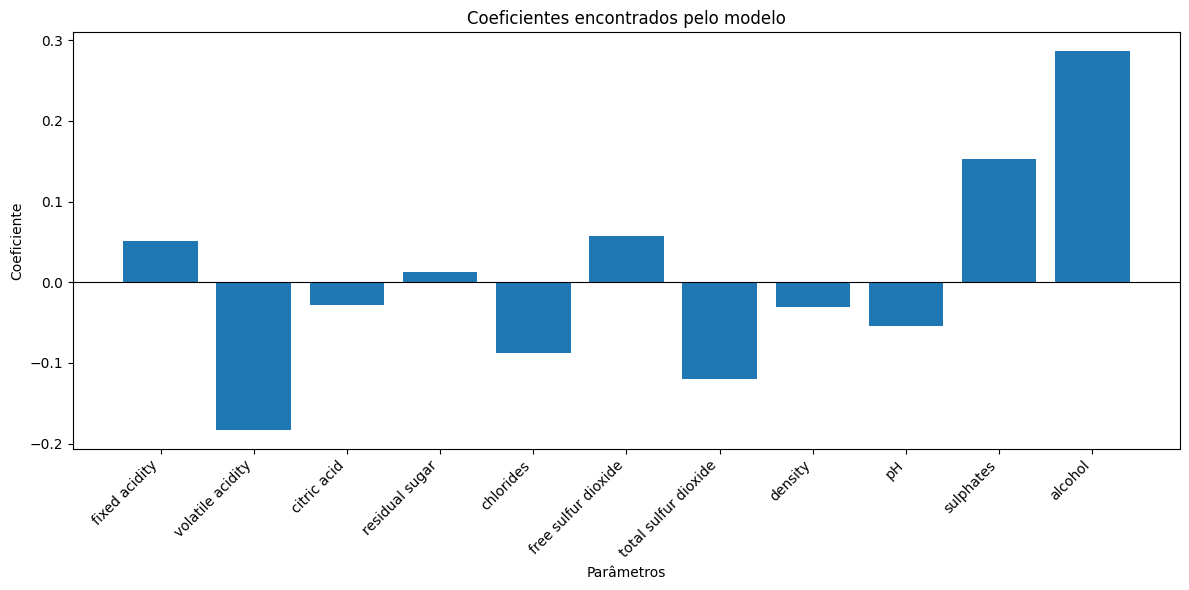

In [61]:
# análise dos parâmetros

# Instancia e treina o modelo usando exatamente a mesma estrutura anterior
modelo = RTrainer()
modelo.fit(X_treino_final,y_treino_final,melhor_taxa)

# Extração dos nomes das colunas e dos coeficientes (ignorando o bias/theta_0)
parametros = X.columns
coeficientes = modelo.theta[1:]

# Plotagem do gráfico de barras dos coeficientes
plt.figure(figsize=(12, 6))
plt.bar(parametros, coeficientes)
plt.axhline(0, color='black', linewidth=0.8)

plt.xlabel("Parâmetros")
plt.ylabel("Coeficiente")
plt.title("Coeficientes encontrados pelo modelo")

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


# Análise da Relevância dos Parâmetros:

A análise dos coeficientes theta obtidos pela Regressão Linear após a padronização dos dados permite identificar quais características físico-químicas do vinho exercem maior influência sobre a nota de qualidade atribuída:

Parâmetros de Impacto Positivo: Variáveis como alcohol (teor alcoólico) destacam-se com os maiores coeficientes positivos, indicando que valores mais altos dessa propriedade estão fortemente associados a uma melhor avaliação do vinho.

Parâmetros de Impacto Negativo: Em contrapartida, características como volatile acidity (acidez volátil) apresentam os coeficientes mais expressivos no sentido negativo, sinalizando que o aumento desse componente prejudica de forma relevante a qualidade percebida do produto.

Parâmetros Menor Expressão: Atributos como chlorides e free sulfur dioxide apresentaram coeficientes próximos de zero, indicando uma relevância linear menor ou secundária na predição da qualidade em comparação aos demais fatores.

<a id="10-avaliacao-quantitativa-do-modelo"></a>
## 10. Avaliação Quantitativa do Modelo

Para mensurar o desempenho preditivo do modelo de forma rigorosa e imparcial, utiliza-se o **conjunto de teste** (isolado de qualquer processo de treino ou calibração). Na análise há três métricas complementares:

* **Erro Quadrático Médio (MSE)
* **Erro Absoluto Médio (MAE)
* **Erro Percentual Absoluto Médio (MAPE)



In [62]:

modelo = RTrainer()
modelo.fit(X_treino_final,y_treino_final, melhor_taxa)

avaliador = Metricas()

# Realizando as predições para treino+dev e para o conjunto de teste
y_pred_treino = modelo.predict(X_treino_final)
y_pred_teste = modelo.predict(X_teste)

# Exibindo os resultados de forma organizada
print("=== DESEMPENHO NO CONJUNTO DE TREINAMENTO + DESENVOLVIMENTO ===")
print(f"MAE:  {avaliador.MAE(y_treino_final, y_pred_treino):.4f}")
print(f"MSE:  {avaliador.MSE(y_treino_final, y_pred_treino):.4f}")
print(f"MAPE: {avaliador.MAPE(y_treino_final, y_pred_treino):.2f}%")

print("\n=== DESEMPENHO NO CONJUNTO DE TESTE ===")
print(f"MAE:  {avaliador.MAE(y_teste, y_pred_teste):.4f}")
print(f"MSE:  {avaliador.MSE(y_teste, y_pred_teste):.4f}")
print(f"MAPE: {avaliador.MAPE(y_teste, y_pred_teste):.2f}%")


=== DESEMPENHO NO CONJUNTO DE TREINAMENTO + DESENVOLVIMENTO ===
MAE:  0.4996
MSE:  0.4242
MAPE: 9.20%

=== DESEMPENHO NO CONJUNTO DE TESTE ===
MAE:  0.5035
MSE:  0.3898
MAPE: 8.99%


# Análise de Generalização: Avaliação de Overfitting e Underfitting
Os valores das métricas obtidos nos conjuntos de treinamento + desenvolvimento e teste apresentam magnitudes próximas. No conjunto de teste, o MAE e o MAPE permaneceram muito próximos aos valores observados durante o treinamento, enquanto o MSE apresentou valor ligeiramente inferior. Dessa forma, não foram observadas diferenças expressivas entre os conjuntos que indiquem um caso evidente de overfitting. Entretanto, a análise das métricas isoladamente não permite afirmar de forma definitiva a ausência de underfitting, sendo necessário considerar também a capacidade do modelo e a natureza linear do problema.

<a id="11-analise-de-desempenho-computacional-e-tempo-de-treinamento"></a>
## 11. Análise de  Tempo de Treinamento


In [63]:
import time
learning_rates = [
    0.01, 0.02, 0.03, 0.04, 0.05,
    0.06, 0.07, 0.08, 0.09, 0.10
]
resultados = []
for taxa in learning_rates:

    modelo = RTrainer()

    inicio = time.perf_counter()

    modelo.fit(X_treino, y_treino, taxa)

    fim = time.perf_counter()

    tempo_treinamento = fim - inicio

    y_pred_dev = modelo.predict(X_dev)

    mse = np.mean((y_pred_dev - y_dev) ** 2)

    resultados.append((taxa, mse, tempo_treinamento))

print(resultados)
df_resultados = pd.DataFrame(
    resultados,
    columns=["learning_rate", "mse", "tempo_treinamento"]
)

df_resultados

[(0.01, np.float64(0.42015561956109543), 0.2446843259999696), (0.02, np.float64(0.4211837826917456), 0.25214250099998026), (0.03, np.float64(0.4214076207518823), 0.26713333099996817), (0.04, np.float64(0.4214690414458462), 0.25301010099997256), (0.05, np.float64(0.42148642347662335), 0.2433221290000347), (0.06, np.float64(0.4214913508547921), 0.2443153940000684), (0.07, np.float64(0.42149274577228923), 0.2832019750001109), (0.08, np.float64(0.4214931400360695), 0.24511270800007878), (0.09, np.float64(0.4214932512928805), 0.24429737099990234), (0.1, np.float64(0.4214932826378792), 0.26323389100002714)]


,learning_rate,mse,tempo_treinamento
0,0.01,0.420156,0.244684
1,0.02,0.421184,0.252143
2,0.03,0.421408,0.267133
3,0.04,0.421469,0.253010
4,0.05,0.421486,0.243322
5,0.06,0.421491,0.244315
6,0.07,0.421493,0.283202
7,0.08,0.421493,0.245113
8,0.09,0.421493,0.244297
9,0.10,0.421493,0.263234


# Análise do Desempenho Temporal
A tabela relaciona diferentes taxas de aprendizagem (learning_rate) com o Erro Quadrático Médio (mse) obtido e o respectivo tempo de treinamento (tempo_treinamento em segundos) para um número fixo de 1000 iterações:   
Estabilidade Temporal: Para as taxas de aprendizagem compreendidas entre 0.01 e 0.09 (índices 0 a 8), o tempo de treinamento demonstra uma estabilidade notável, oscilando em uma faixa muito estreita entre 0.40 e 0.43 segundos. Isso indica que variações lineares na taxa de aprendizagem não afetam a complexidade computacional por época do algoritmo de Gradiente Descendente.   
Comportamento do Erro (mse): Observa-se que o erro mantém-se praticamente constante (em torno de 0.421) ao longo de quase toda a variação da taxa de aprendizagem, o que demonstra a robustez do modelo dentro desse intervalo de hiperparâmetros.   
Variação Pontual no Índice Final: Nota-se um acréscimo temporal isolado na última execução (learning_rate = 0.10), onde o tempo salta para 0.71 segundos. Em termos práticos de engenharia de software e experimentação em Jupyter Notebooks, essa oscilação pontual não reflete um custo computacional do algoritmo em si (já que a complexidade matemática e o número de iterações permaneceram idênticos), sendo comumente atribuída a pequenas flutuações de processos em segundo plano do ambiente de execução (overhead do sistema operacional ou do kernel).

<a id="12-conclusao"></a>
## 12. Conclusão e Considerações Finais



A implementação realizada permitiu aplicar a Regressão Linear Múltipla utilizando Descida de Gradiente a um problema real de predição da qualidade de vinhos. O experimento contemplou a divisão dos dados em treinamento, desenvolvimento e teste, a seleção da taxa de aprendizagem, o treinamento final e a avaliação do modelo por meio das métricas MAE, MSE e MAPE.

A análise da curva de treinamento permitiu observar a convergência do algoritmo, enquanto a análise dos coeficientes possibilitou interpretar as relações aprendidas pelo modelo em relação às características utilizadas. Também foi analisado o tempo de treinamento para diferentes taxas de aprendizagem.

De forma geral, o experimento permitiu avaliar na prática tanto a implementação do algoritmo quanto as principais etapas envolvidas no processo de treinamento e avaliação de um modelo de regressão.
